In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
input_folder = r"C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images"

output_folder = r"C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Histogram Enhanced Images"

os.makedirs(output_folder, exist_ok=True)

print("Folders ready")

Folders ready


In [4]:
image1 = cv2.imread(os.path.join(input_folder, "1.png"))
image2 = cv2.imread(os.path.join(input_folder, "2.png"))
image3 = cv2.imread(os.path.join(input_folder, "3.png"))
image4 = cv2.imread(os.path.join(input_folder, "4.png"))
image5 = cv2.imread(os.path.join(input_folder, "5.png"))

images = [image1, image2, image3, image4, image5]

for i, img in enumerate(images, 1):
    if img is None:
        print("Image", i, "not found")
    else:
        print("Image", i, "loaded successfully")

Image 1 loaded successfully
Image 2 loaded successfully
Image 3 loaded successfully
Image 4 loaded successfully
Image 5 loaded successfully


In [5]:
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(image3, cv2.COLOR_BGR2GRAY)
gray4 = cv2.cvtColor(image4, cv2.COLOR_BGR2GRAY)
gray5 = cv2.cvtColor(image5, cv2.COLOR_BGR2GRAY)

gray_images = [gray1, gray2, gray3, gray4, gray5]

print("All images converted to grayscale")

All images converted to grayscale


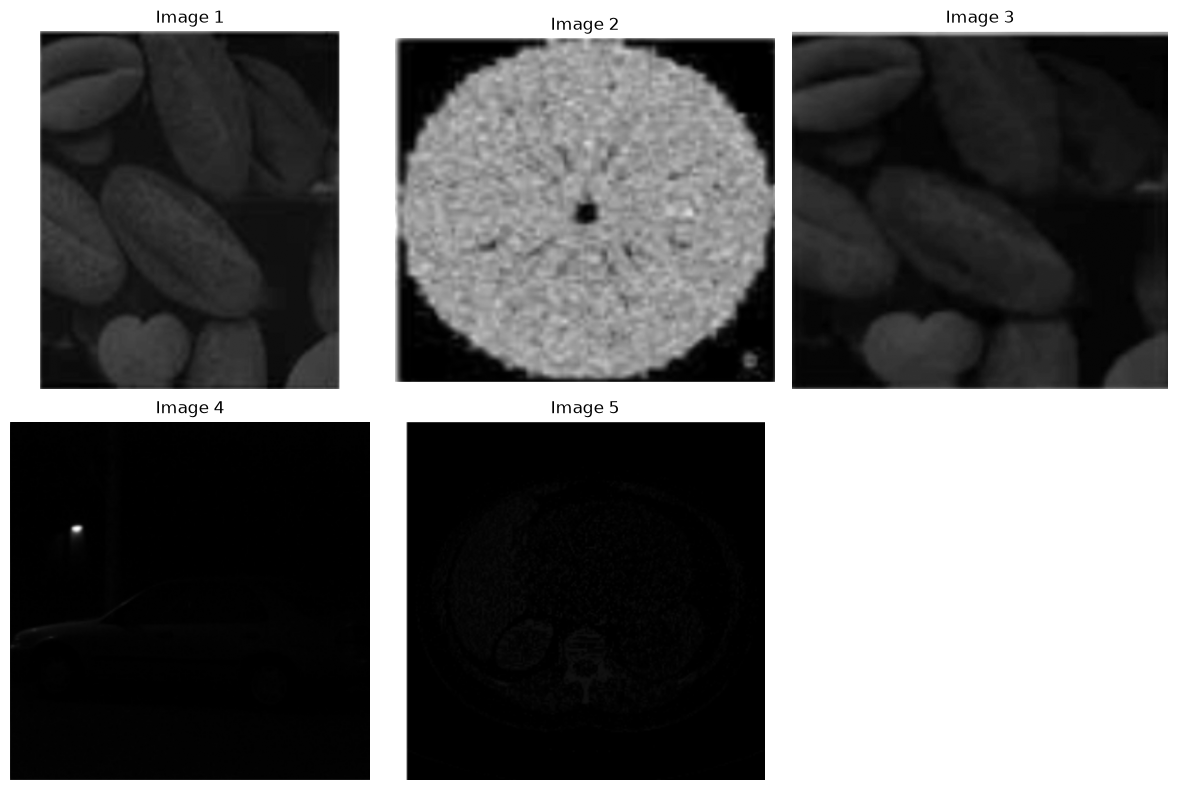

In [6]:
plt.figure(figsize=(12, 8))
for i, img in enumerate(gray_images, 1):
    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title("Image {}".format(i))
    plt.axis("off")
plt.tight_layout()
plt.show()

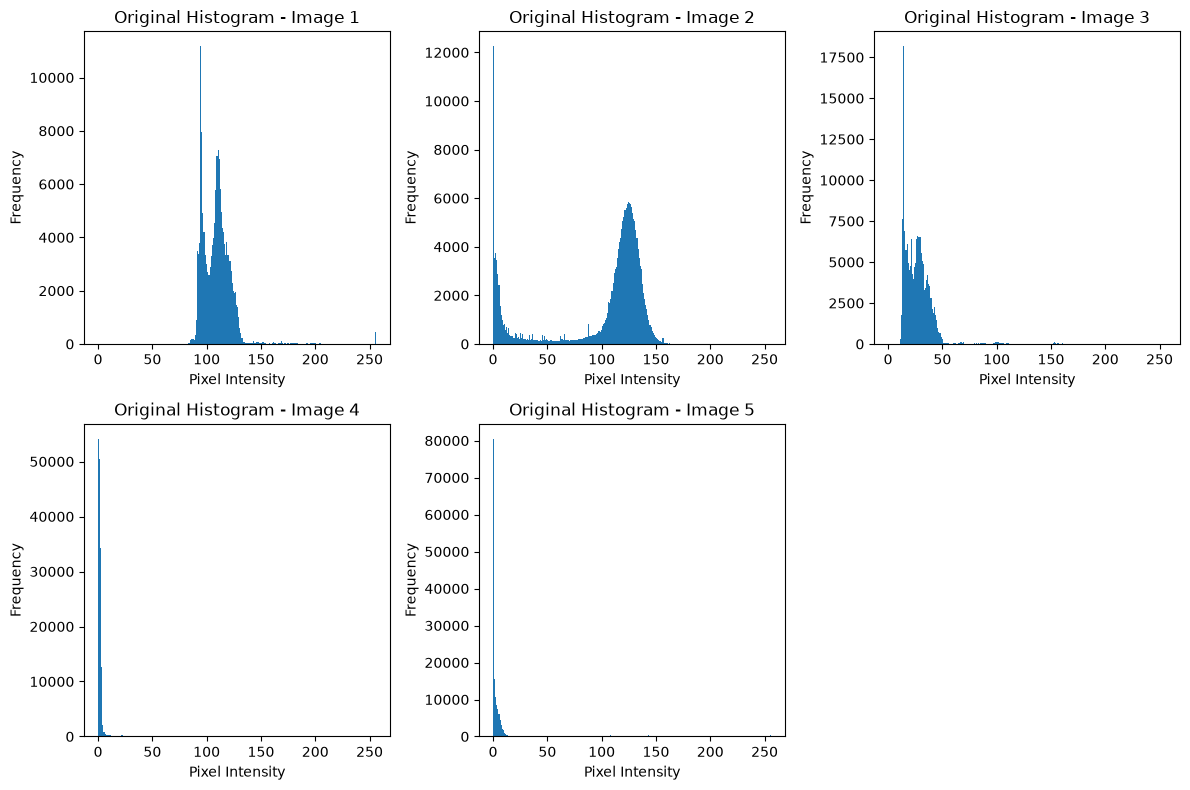

In [7]:
plt.figure(figsize=(12, 8))

for i, img in enumerate(gray_images, 1):

    plt.subplot(2, 3, i)

    plt.hist(
        img.ravel(),
        bins=256,
        range=[0, 256]
    )

    plt.title("Original Histogram - Image {}".format(i))

    plt.xlabel("Pixel Intensity")

    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

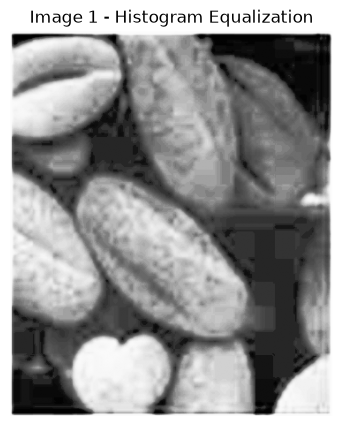

In [8]:
equalized1 = cv2.equalizeHist(gray1)

cv2.imwrite(
    os.path.join(
        output_folder,
        "image1_equalized.png"
    ),
    equalized1
)

plt.figure(figsize=(6, 5))

plt.imshow(equalized1, cmap="gray")

plt.title("Image 1 - Histogram Equalization")

plt.axis("off")

plt.show()

In [9]:
def histogram_matching(source, reference):

    source_hist = np.bincount(
        source.ravel(),
        minlength=256
    )

    reference_hist = np.bincount(
        reference.ravel(),
        minlength=256
    )

    source_cdf = np.cumsum(source_hist).astype(np.float64)

    reference_cdf = np.cumsum(
        reference_hist
    ).astype(np.float64)

    source_cdf /= source_cdf[-1]

    reference_cdf /= reference_cdf[-1]

    lookup_table = np.zeros(
        256,
        dtype=np.uint8
    )

    for source_value in range(256):

        difference = np.abs(
            reference_cdf -
            source_cdf[source_value]
        )

        lookup_table[source_value] = np.argmin(
            difference
        )

    matched = lookup_table[source]

    return matched

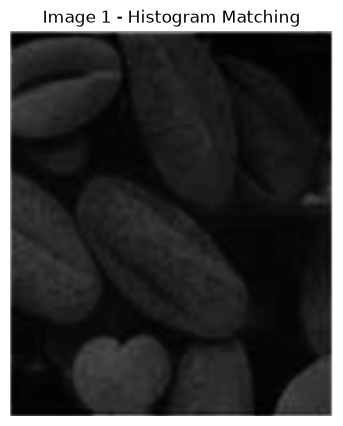

In [11]:
reference_image = gray3

matched1 = histogram_matching(gray1, reference_image)
cv2.imwrite(os.path.join(output_folder,"image1_matched.png"),matched1)
plt.figure(figsize=(6, 5))
plt.imshow(matched1, cmap="gray")
plt.title("Image 1 - Histogram Matching")
plt.axis("off")
plt.show()

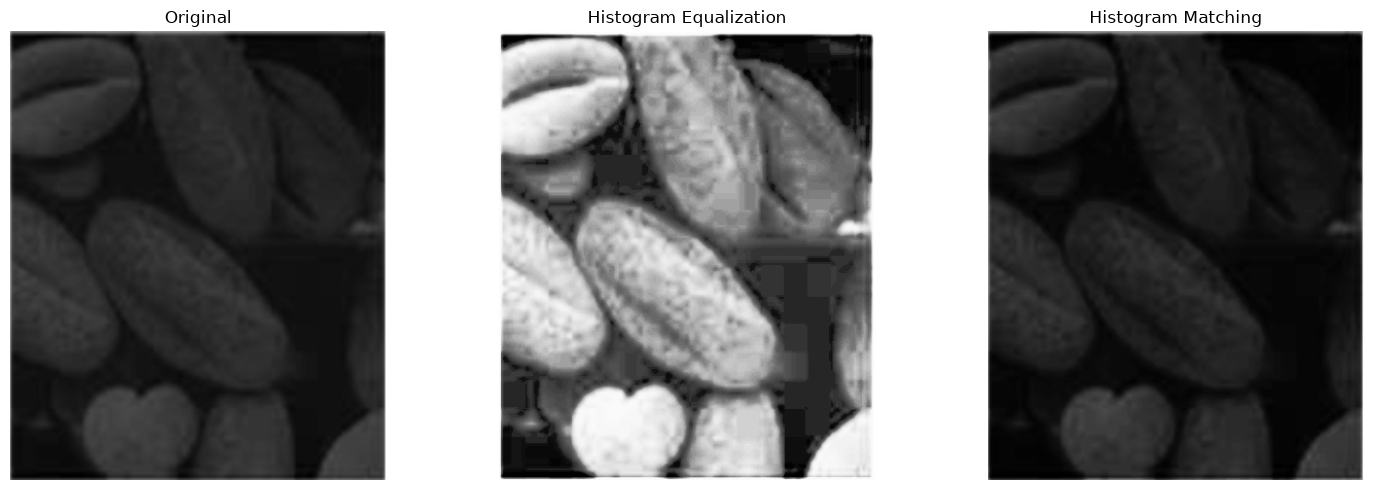

In [12]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized1, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched1, cmap="gray")
plt.title("Histogram Matching")
plt.axis("off")

plt.tight_layout()
plt.show()

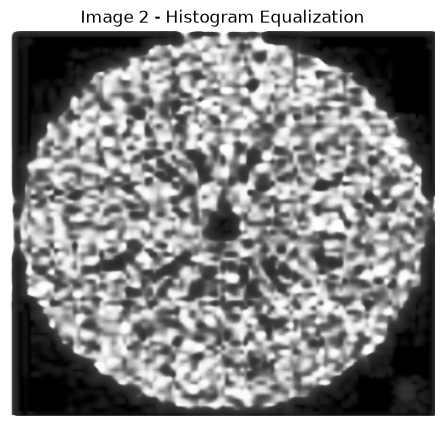

In [13]:
equalized2 = cv2.equalizeHist(gray2)

cv2.imwrite(os.path.join(output_folder,"image2_equalized.png"),equalized2)
plt.figure(figsize=(6, 5))
plt.imshow(equalized2, cmap="gray")
plt.title("Image 2 - Histogram Equalization")
plt.axis("off")
plt.show()

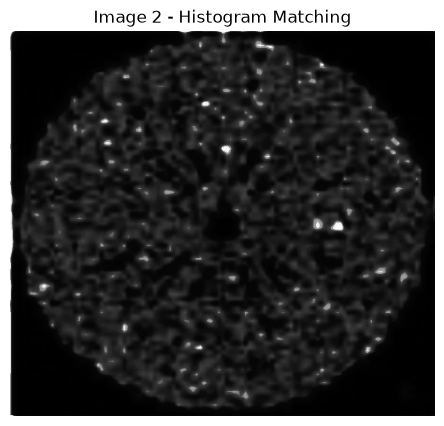

In [14]:
matched2 = histogram_matching(gray2,reference_image)

cv2.imwrite(os.path.join(output_folder,"image2_matched.png"),matched2)
plt.figure(figsize=(6, 5))
plt.imshow(matched2, cmap="gray")
plt.title("Image 2 - Histogram Matching")
plt.axis("off")
plt.show()

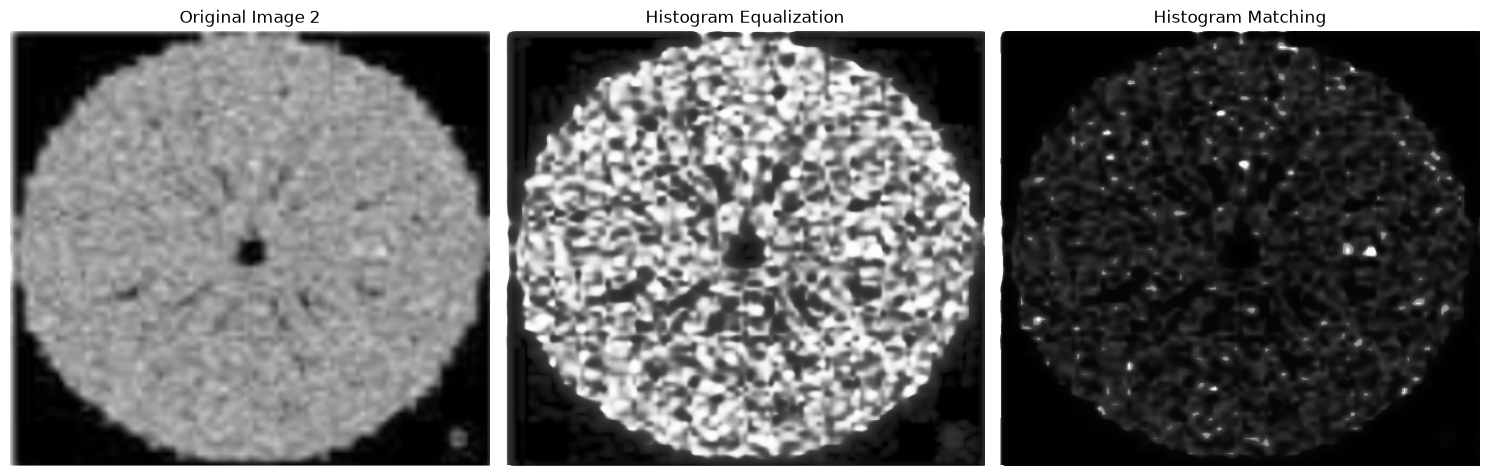

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray2, cmap="gray")
plt.title("Original Image 2")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized2, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched2, cmap="gray")
plt.title("Histogram Matching")
plt.axis("off")

plt.tight_layout()
plt.show()

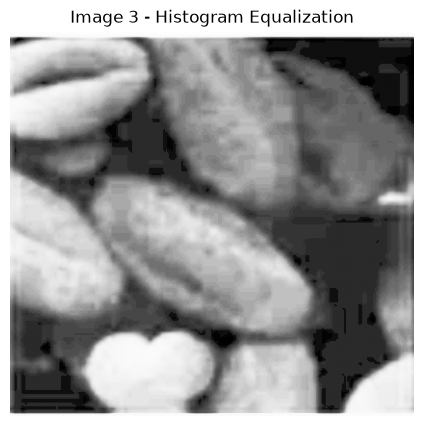

In [16]:
equalized3 = cv2.equalizeHist(gray3)

cv2.imwrite(os.path.join(output_folder,"image3_equalized.png"),equalized3)
plt.figure(figsize=(6, 5))
plt.imshow(equalized3, cmap="gray")
plt.title("Image 3 - Histogram Equalization")
plt.axis("off")
plt.show()

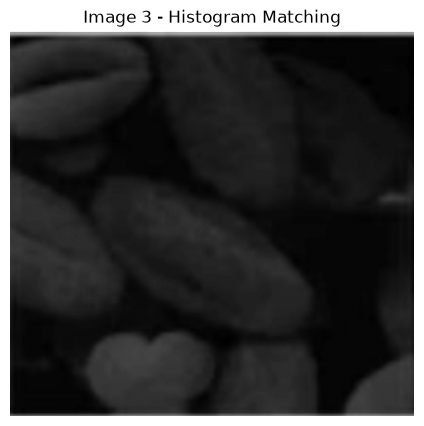

In [17]:
matched3 = histogram_matching(gray3,reference_image)

cv2.imwrite(os.path.join(output_folder,"image3_matched.png"),matched3)
plt.figure(figsize=(6, 5))
plt.imshow(matched3, cmap="gray")
plt.title("Image 3 - Histogram Matching")
plt.axis("off")
plt.show()

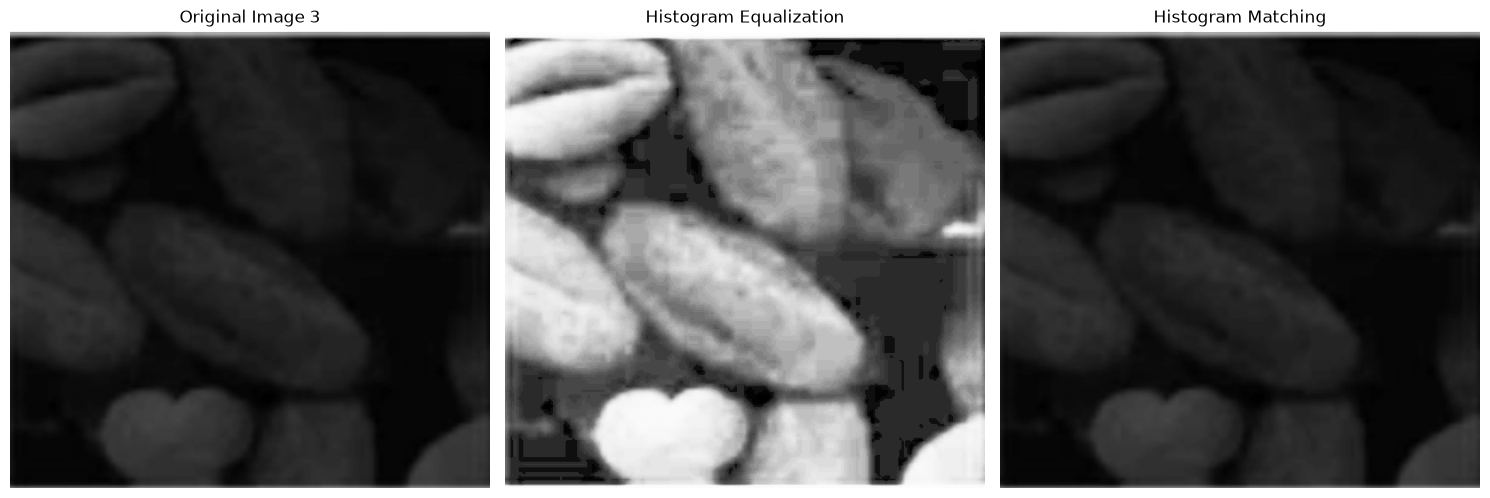

In [18]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray3, cmap="gray")
plt.title("Original Image 3")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized3, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched3, cmap="gray")
plt.title("Histogram Matching")
plt.axis("off")

plt.tight_layout()
plt.show()

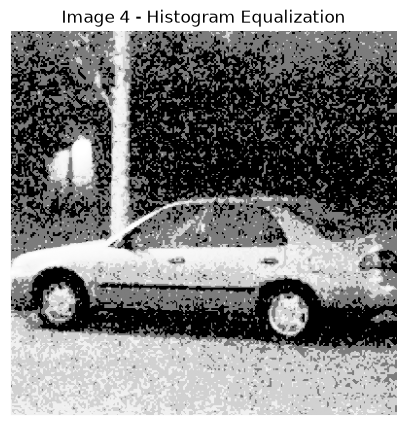

In [19]:
equalized4 = cv2.equalizeHist(gray4)

cv2.imwrite(os.path.join(output_folder,"image4_equalized.png"),equalized4)
plt.figure(figsize=(6, 5))
plt.imshow(equalized4, cmap="gray")
plt.title("Image 4 - Histogram Equalization")
plt.axis("off")
plt.show()

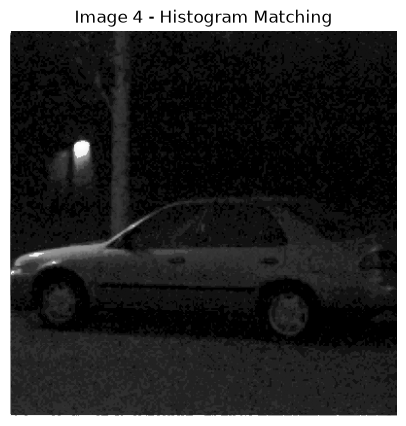

In [20]:
matched4 = histogram_matching(gray4,reference_image)

cv2.imwrite(os.path.join(output_folder,"image4_matched.png"),matched4)
plt.figure(figsize=(6, 5))
plt.imshow(matched4, cmap="gray")
plt.title("Image 4 - Histogram Matching")
plt.axis("off")
plt.show()

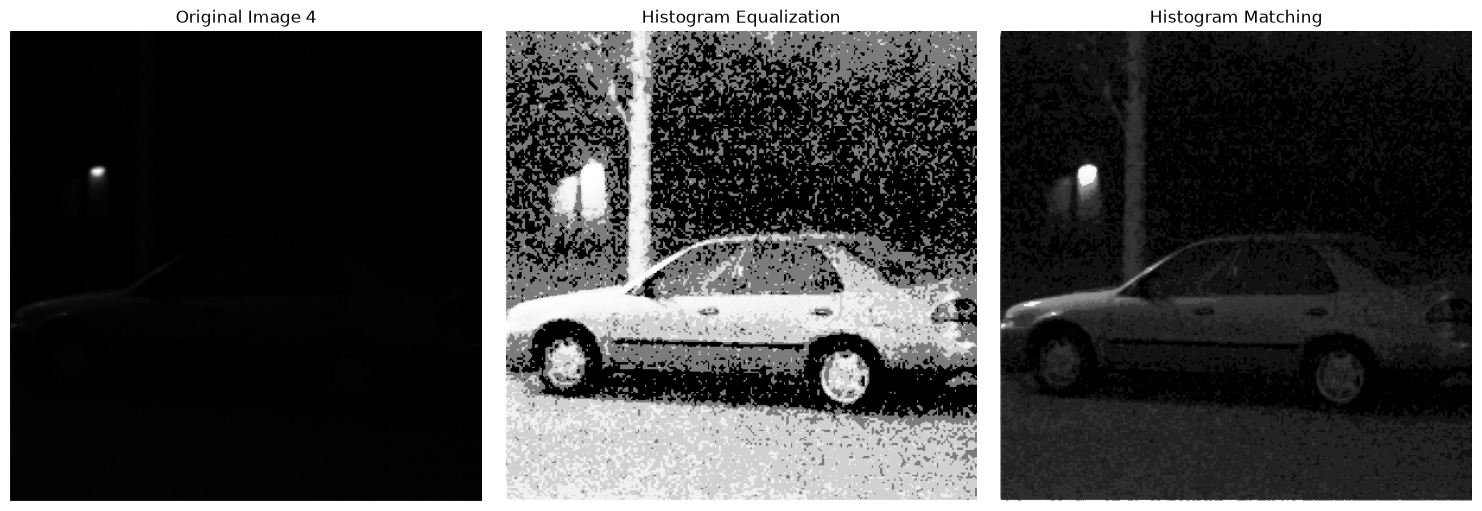

In [21]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray4, cmap="gray")
plt.title("Original Image 4")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized4, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched4, cmap="gray")
plt.title("Histogram Matching")
plt.axis("off")

plt.tight_layout()
plt.show()

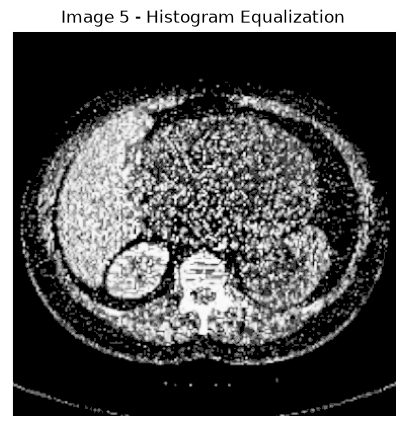

In [22]:
equalized5 = cv2.equalizeHist(gray5)

cv2.imwrite(os.path.join(output_folder,"image5_equalized.png"),equalized5)
plt.figure(figsize=(6, 5))
plt.imshow(equalized5, cmap="gray")
plt.title("Image 5 - Histogram Equalization")
plt.axis("off")
plt.show()

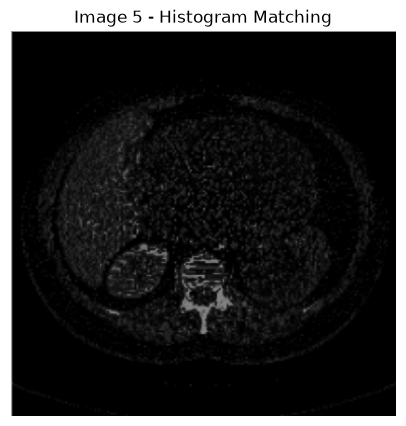

In [23]:
matched5 = histogram_matching(gray5,reference_image)

cv2.imwrite(os.path.join(output_folder,"image5_matched.png"),matched5)
plt.figure(figsize=(6, 5))
plt.imshow(matched5, cmap="gray")
plt.title("Image 5 - Histogram Matching")
plt.axis("off")
plt.show()

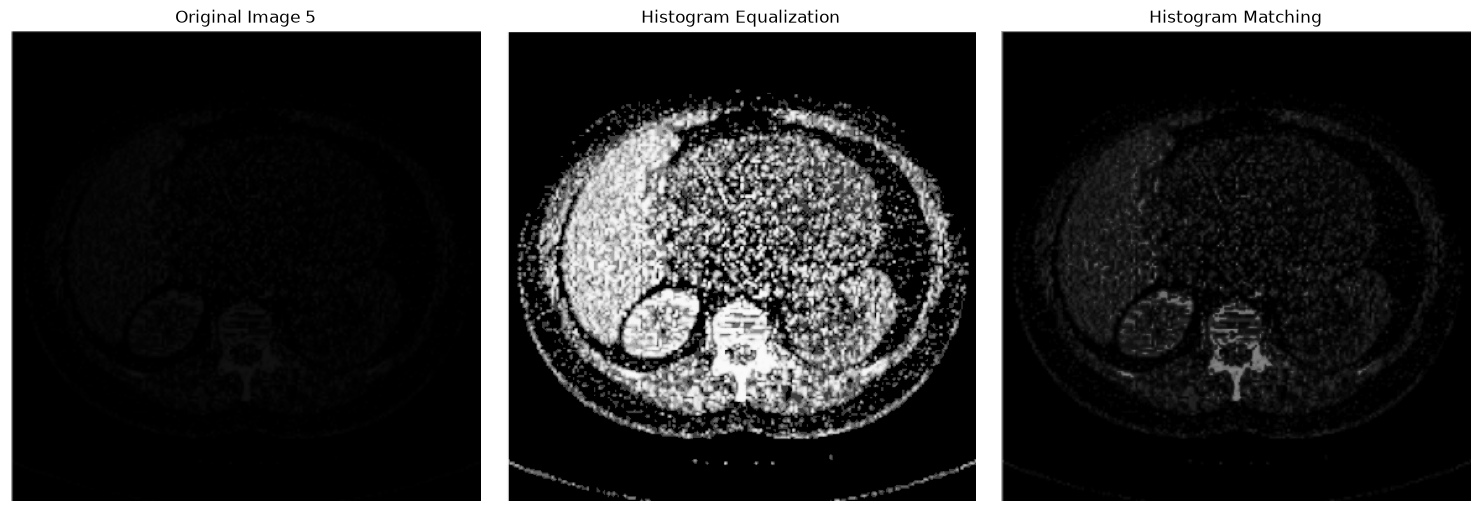

In [24]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray5, cmap="gray")
plt.title("Original Image 5")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized5, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched5, cmap="gray")
plt.title("Histogram Matching")
plt.axis("off")

plt.tight_layout()
plt.show()

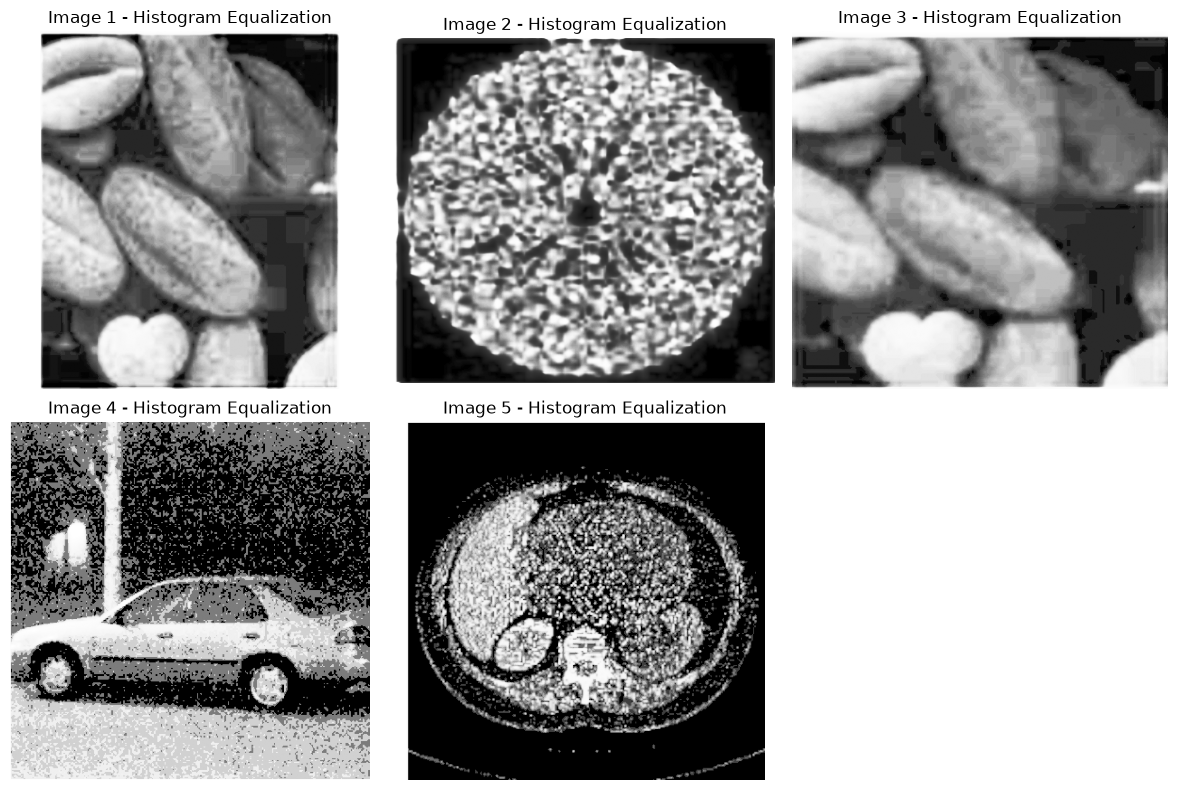

In [25]:
equalized_images = [equalized1,equalized2,equalized3,equalized4,equalized5]

plt.figure(figsize=(12, 8))

for i, img in enumerate(equalized_images, 1):

    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title("Image {} - Histogram Equalization".format(i))
    plt.axis("off")

plt.tight_layout()
plt.show()

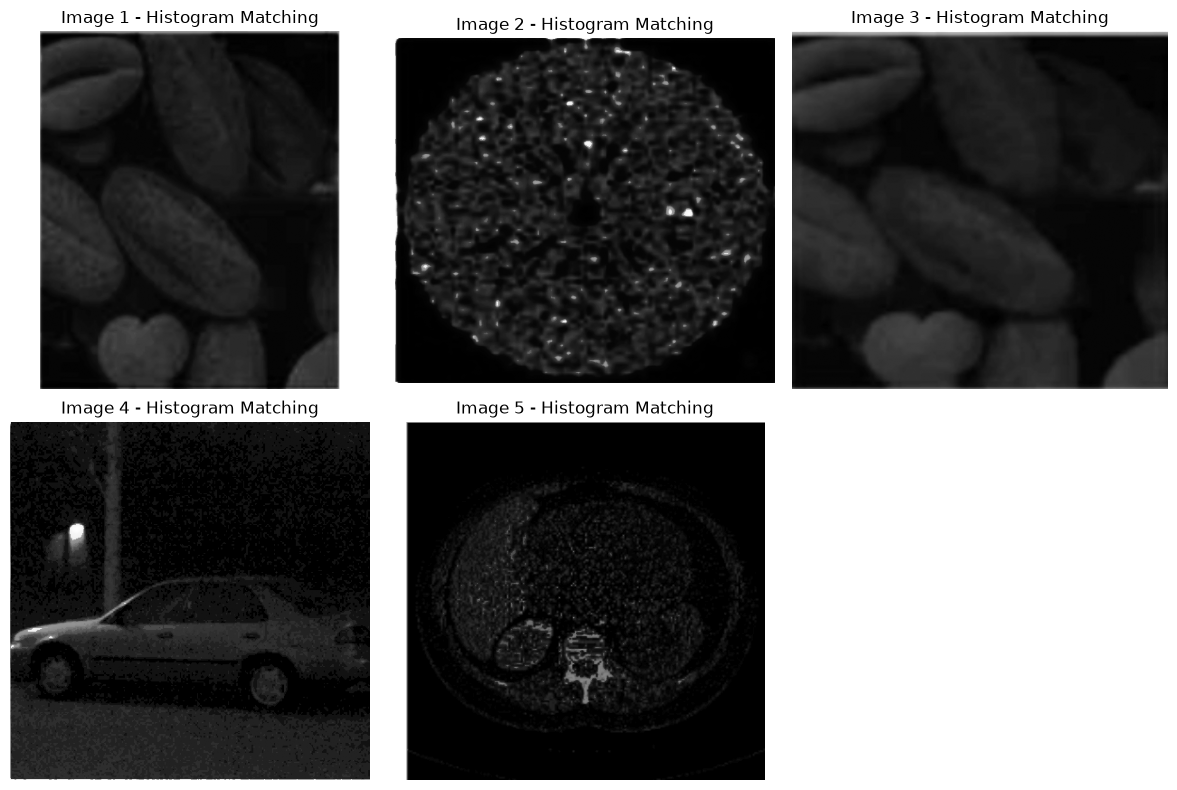

In [26]:
matched_images = [matched1,matched2,matched3,matched4,matched5]

plt.figure(figsize=(12, 8))

for i, img in enumerate(matched_images, 1):

    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title("Image {} - Histogram Matching".format(i))
    plt.axis("off")

plt.tight_layout()
plt.show()

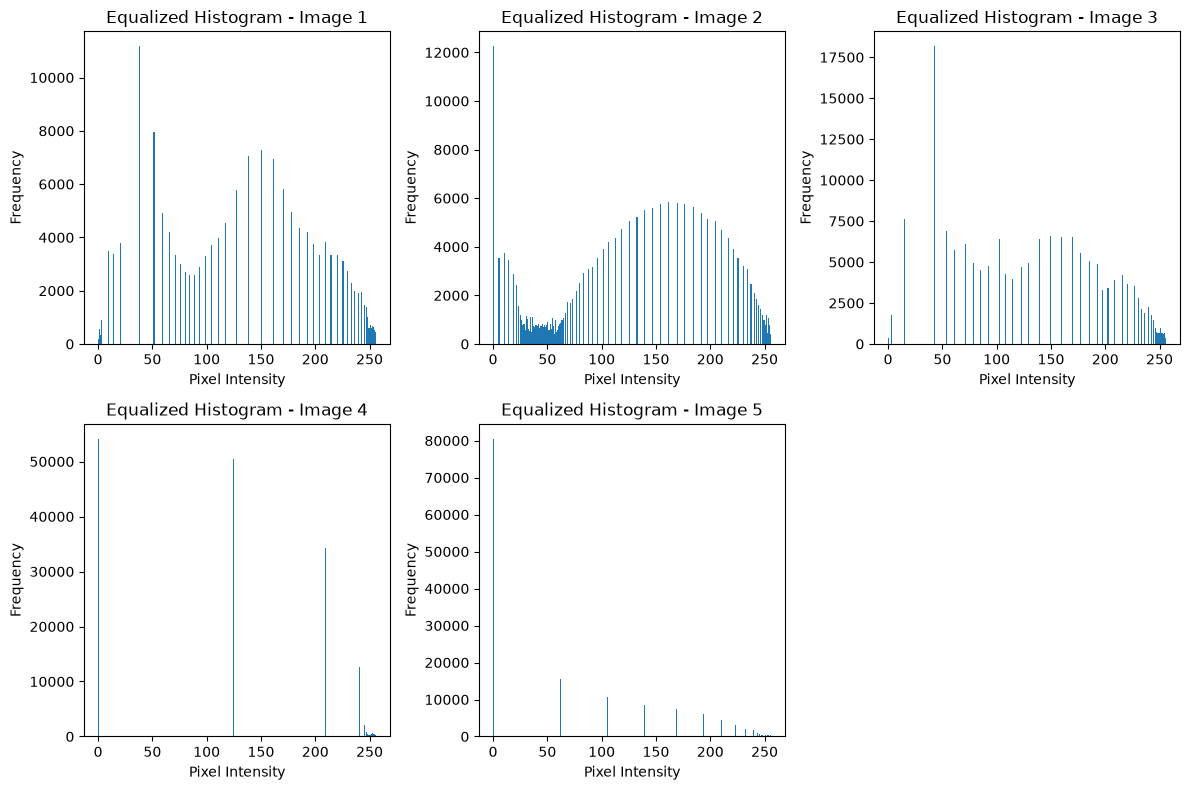

In [27]:
plt.figure(figsize=(12, 8))

for i, img in enumerate(equalized_images, 1):
    plt.subplot(2, 3, i)
    plt.hist(img.ravel(),bins=256,range=[0, 256])

    plt.title("Equalized Histogram - Image {}".format(i))

    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

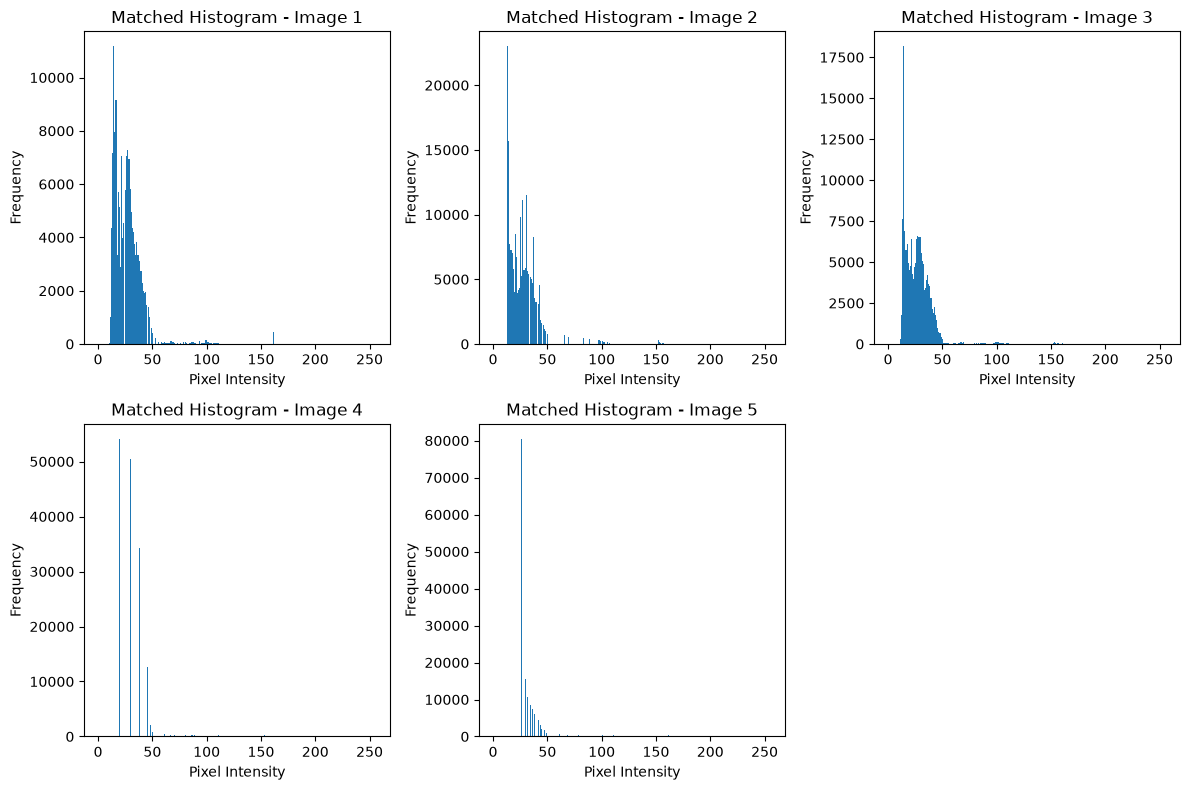

In [28]:
plt.figure(figsize=(12, 8))

for i, img in enumerate(matched_images, 1):
    plt.subplot(2, 3, i)
    plt.hist(img.ravel(),bins=256,range=[0, 256])

    plt.title("Matched Histogram - Image {}".format(i))

    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

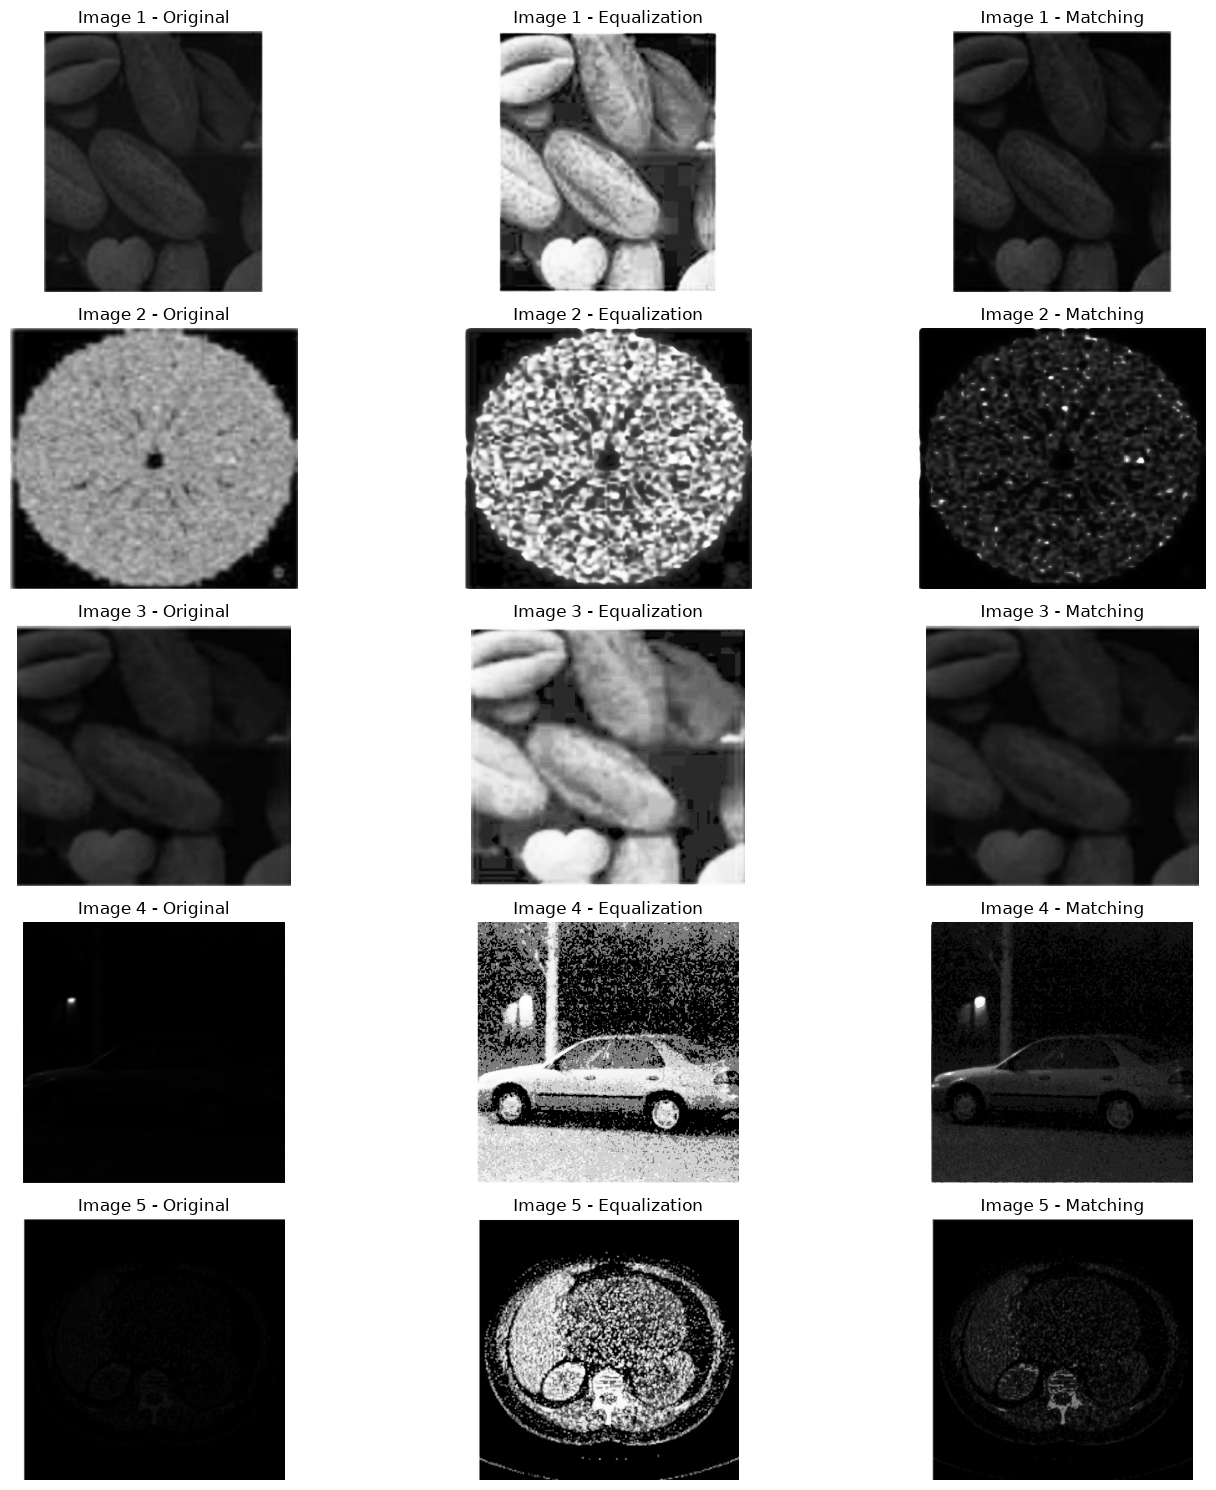

In [29]:
plt.figure(figsize=(15, 15))

for i in range(5):

    plt.subplot(5, 3, 3*i + 1)

    plt.imshow(gray_images[i],cmap="gray")

    plt.title("Image {} - Original".format(i + 1))

    plt.axis("off")


    plt.subplot(5, 3, 3*i + 2)

    plt.imshow(equalized_images[i],cmap="gray")

    plt.title("Image {} - Equalization".format(i + 1))

    plt.axis("off")


    plt.subplot(5, 3, 3*i + 3)

    plt.imshow(matched_images[i],cmap="gray")

    plt.title("Image {} - Matching".format(i + 1))

    plt.axis("off")


plt.tight_layout()
plt.show()